In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.family"] = "Arial"
import seaborn as sns

from additives_microbiota.group_statistics import test_quartile_differences, test_group_differences
from additives_microbiota.constants import ADDITIVE_VARS, MIXTURES


import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrices

from additives_microbiota.plotting import process_string, process_string_pretty_vars, pretty_var_names
from additives_microbiota.regression_modeling import fit_regression_model, calculate_vif, forest_plot

### Load Metadata

In [2]:
meta = pd.read_csv("../../data/metadata_files/meta_zscores.csv", index_col=0)

bmi_order = ["Underweight", "Normal", "Overweight", "Obese"]
meta["bmi_cat"] = pd.Categorical(meta["bmi_cat"], categories=bmi_order, ordered=True)

meta["HEI_Quartile"] = meta["HEI_Quartile"].astype("category")
meta["HEI_Quartile"] = meta["HEI_Quartile"].cat.set_categories(
    ["Q1", "Q2", "Q3", "Q4"], ordered=True
)

meta["age_group_2"] = meta["age_group_2"].astype("category")
meta["age_group_2"] = meta["age_group_2"].cat.set_categories(
    ["<35", "35-50", ">50"], ordered=True
)

In [3]:
barcoded_foods_sugar_consumption = pd.read_csv(
    "../../data/additive_analysis_files/avg_daily_barcoded_foods_sugar_consumption.csv"
)

print(barcoded_foods_sugar_consumption["barcoded_foods_sugar_eaten"].describe())

bfs_meta = meta.merge(barcoded_foods_sugar_consumption, on="subject_key", how="left")
print(bfs_meta.shape)

count    1009.000000
mean       18.713957
std        15.594064
min         0.000000
25%         7.604786
50%        14.926600
75%        25.057231
max       107.826484
Name: barcoded_foods_sugar_eaten, dtype: float64
(975, 266)


In [4]:
bfs_meta[
    [
        "barcoded_foods_sugar_eaten",
        "shannon_entropy",
        "pielou_evenness",
        "observed_features",
        "faith_pd",
    ]
    + MIXTURES
    + ADDITIVE_VARS
].corr()["barcoded_foods_sugar_eaten"].sort_values(ascending=False)

barcoded_foods_sugar_eaten                           1.000000
Mixture1                                             0.568447
thickeners_stabilizers_emulsifiers_gelling_agents    0.535569
ph_regulators_anti_caking_leavening_agents           0.522393
preservatives_antioxidants                           0.355329
colorants                                            0.326768
Mixture2                                             0.201404
flavor_enhancers                                     0.200380
sweeteners_glazing_agents                            0.166218
other_additives                                      0.125985
Mixture3                                             0.071430
observed_features                                   -0.112015
faith_pd                                            -0.129895
shannon_entropy                                     -0.141027
pielou_evenness                                     -0.142713
Name: barcoded_foods_sugar_eaten, dtype: float64

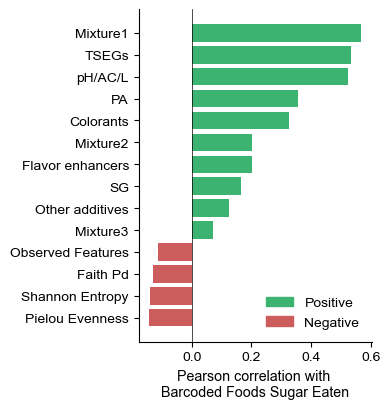

In [5]:
# Apply process_string_vars to y axis labels in the bar plot
corrs = (
    bfs_meta[
        [
            "barcoded_foods_sugar_eaten",
            "shannon_entropy",
            "pielou_evenness",
            "observed_features",
            "faith_pd",
        ]
        + MIXTURES
        + ADDITIVE_VARS
    ]
    .corr()["barcoded_foods_sugar_eaten"]
    .drop("barcoded_foods_sugar_eaten")
    .sort_values()
)

# Process the y-axis labels using process_string_vars
pretty_labels = [process_string_pretty_vars(v) for v in corrs.index]

# Prepare color map: green for positive, red for negative
bar_colors = ["mediumseagreen" if v > 0 else "indianred" for v in corrs.values]

fig, ax = plt.subplots(figsize=(4, len(corrs) * 0.3))
bars = ax.barh(pretty_labels, corrs.values, color=bar_colors)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("Pearson correlation with \nBarcoded Foods Sugar Eaten", fontsize=10.3)
plt.tight_layout()

# Add legend for color
import matplotlib.patches as mpatches

positive_patch = mpatches.Patch(color="mediumseagreen", label="Positive")
negative_patch = mpatches.Patch(color="indianred", label="Negative")
ax.legend(handles=[positive_patch, negative_patch], loc="lower right", frameon=False)

sns.despine()

plt.savefig(
    "../figures/additive_descriptive/correlation_barcoded_foods_sugar_eaten.png",
    dpi=300,
    bbox_inches="tight",
)

## Comparisons

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.925e-01 U_stat=3.141e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:6.552e-01 U_stat=3.034e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.967e-02 U_stat=3.302e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.149e-01 U_stat=3.209e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.993e-03 U_stat=3.405e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.812e-04 U_stat=3.560e+04
barcoded_foods_sugar_eaten_quartile -> shannon_entropy	Significant differences exist. Kruskal-Wallis statistic: 15.069 p-value: 0.002
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 

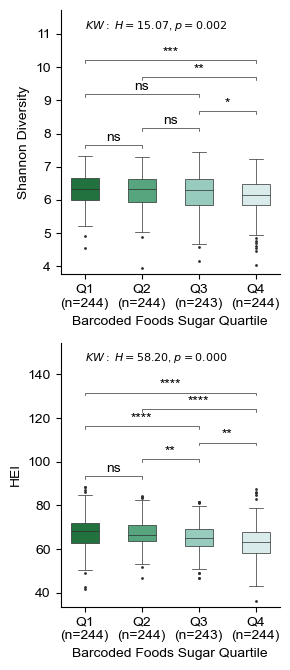

In [6]:
fig, ax = plt.subplots(ncols=1, nrows=2, figsize=(3, 6.8))
test_quartile_differences(
    bfs_meta,
    "barcoded_foods_sugar_eaten",
    "shannon_entropy",
    extremes=False,
    make_quartile=True,
    ax=ax[0],
    palette="BuGn_r",
    ylabel="Shannon Diversity",
)

test_quartile_differences(
    bfs_meta,
    "barcoded_foods_sugar_eaten",
    "HEI",
    extremes=False,
    make_quartile=True,
    ax=ax[1],
    palette="BuGn_r",
)

sns.despine()
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/group_comparison_barcoded_foods_sugar_eaten.png",
    dpi=300,
    bbox_inches="tight",
)

## Running OLS models

In [7]:
demographic_vars = [
    "age",
    "bmi",
    "C(gender)",
    # "HEI",
    "C(language, Treatment(reference='latin'))",
    "defecate_quantity_per_day",
    "C(urbanity, Treatment(reference='rural'))",
    "C(smoking, Treatment(reference='non-smoker'))",
    "energy_kcal_eaten",
    "C(antibiotics_treatment)",
    "alcohol_eaten",
    "batch",
]

In [8]:
sugar_model = fit_regression_model(
    bfs_meta,
    [
        "sweeteners_glazing_agents",
        "barcoded_foods_sugar_eaten",
        "vegetables_fg_eaten",
        "fruits_fg_eaten",
    ],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    # robust=True,
    robust_regression=False,
    do_robust_se=True,
)

sugar_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.205
Model:                            OLS   Adj. R-squared:                  0.187
Method:                 Least Squares   F-statistic:                     11.34
Date:                Wed, 31 Dec 2025   Prob (F-statistic):           6.36e-34
Time:                        22:57:27   Log-Likelihood:                -635.98
No. Observations:                 940   AIC:                             1316.
Df Residuals:                     918   BIC:                             1423.
Df Model:                          21                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   6.6391      0.160     41.401      0.000       6.325       6.953
C(gender)[T.male]                                           0.0614      0.036      1.696      0.090      -0.010       0.132
C(language, Treatment(reference='latin'))[T.german]        -0.0992      0.036     -2.756      0.006      -0.170      -0.029
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0844      0.068     -1.237      0.216      -0.218       0.049
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1389      0.056     -2.461      0.014      -0.250      -0.028
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1052      0.035     -3.036      0.002      -0.173      -0.037
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2013      0.059     -3.432      0.001      -0.316      -0.086
C(antibiotics_treatment)[T.True]                           -0.1179      0.069     -1.715      0.086      -0.253       0.017
batch[T.batch_0682]                                         0.0635      0.064      0.995      0.320      -0.062       0.189
batch[T.batch_1205]                                         0.0785      0.069      1.140      0.254      -0.057       0.214
batch[T.batch_1599]                                        -0.0920      0.068     -1.361      0.173      -0.224       0.040
batch[T.batch_2013]                                        -0.0252      0.068     -0.370      0.712      -0.159       0.108
batch[T.batch_2718]                                        -0.2470      0.068     -3.606      0.000      -0.381      -0.113
sweeteners_glazing_agents                                  -0.0351      0.017     -2.053      0.040      -0.069      -0.002
barcoded_foods_sugar_eaten                                 -0.0023      0.001     -1.705      0.088      -0.005       0.000
vegetables_fg_eaten                                         0.0004      0.000      2.673      0.008       0.000       0.001
fruits_fg_eaten                                             0.0004      0.000      2.215      0.027    4.43e-05       0.001
age                                                         0.0076      0.001      5.148      0.000       0.005       0.011
bmi                                                        -0.0134      0.005     -2.964      0.003      -0.022      -0.005
defecate_quantity_per_day                                  -0.1226      0.023     -5.268      0.000      -0.168      -0.077
energy_kcal_eaten                                       -3.667e-05   4.43e-05     -0.828      0.407      -0.000    5.01e-05
alcohol_eaten                                               0.0014      0.002      0.751      0.452      -0

In [9]:
print(
    sugar_model.cov_params().loc[
        "sweeteners_glazing_agents", "barcoded_foods_sugar_eaten"
    ]
)

calculate_vif(sugar_model, bfs_meta)

-4.0288305686236325e-06


,Variable,VIF
9,batch[T.batch_1599],2.750786
10,batch[T.batch_2013],2.717769
3,"C(urbanity, Treatment(reference='rural'))[T.ur...",2.672631
2,"C(urbanity, Treatment(reference='rural'))[T.se...",2.630587
8,batch[T.batch_1205],2.588543
11,batch[T.batch_2718],2.449004
7,batch[T.batch_0682],2.439703
19,energy_kcal_eaten,1.565896
0,C(gender)[T.male],1.344900
13,barcoded_foods_sugar_eaten,1.329611


### Model with scaled variables

In [10]:
vars_to_scale = [
    "sweeteners_glazing_agents",
    "barcoded_foods_sugar_eaten",
    "vegetables_fg_eaten",
    "fruits_fg_eaten",
] + [
    # "HEI",
    "alcohol_eaten",
    "bmi",
    "age",
    "defecate_quantity_per_day",
    # "eaten_quantity_in_gram",
    "energy_kcal_eaten",
]

bfs_meta_scaled = bfs_meta.copy()
for col in vars_to_scale:
    bfs_meta_scaled[col + "_z"] = (bfs_meta[col] - bfs_meta[col].mean()) / bfs_meta[
        col
    ].std()

sugar_model_scaled = fit_regression_model(
    bfs_meta_scaled,
    [i + "_z" for i in vars_to_scale],
    demographic_vars=[i for i in demographic_vars if i not in vars_to_scale],
    dependent_var="shannon_entropy",
    robust_regression=False,
    do_robust_se=True,
)

sugar_model_scaled.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.205
Model:                            OLS   Adj. R-squared:                  0.187
Method:                 Least Squares   F-statistic:                     11.34
Date:                Wed, 31 Dec 2025   Prob (F-statistic):           6.36e-34
Time:                        22:57:27   Log-Likelihood:                -635.98
No. Observations:                 940   AIC:                             1316.
Df Residuals:                     918   BIC:                             1423.
Df Model:                          21                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   6.4794      0.074     87.087      0.000       6.334       6.625
C(gender)[T.male]                                           0.0614      0.036      1.696      0.090      -0.010       0.132
C(language, Treatment(reference='latin'))[T.german]        -0.0992      0.036     -2.756      0.006      -0.170      -0.029
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0844      0.068     -1.237      0.216      -0.218       0.049
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1389      0.056     -2.461      0.014      -0.250      -0.028
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1052      0.035     -3.036      0.002      -0.173      -0.037
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2013      0.059     -3.432      0.001      -0.316      -0.086
C(antibiotics_treatment)[T.True]                           -0.1179      0.069     -1.715      0.086      -0.253       0.017
batch[T.batch_0682]                                         0.0635      0.064      0.995      0.320      -0.062       0.189
batch[T.batch_1205]                                         0.0785      0.069      1.140      0.254      -0.057       0.214
batch[T.batch_1599]                                        -0.0920      0.068     -1.361      0.173      -0.224       0.040
batch[T.batch_2013]                                        -0.0252      0.068     -0.370      0.712      -0.159       0.108
batch[T.batch_2718]                                        -0.2470      0.068     -3.606      0.000      -0.381      -0.113
sweeteners_glazing_agents_z                                -0.0560      0.027     -2.053      0.040      -0.109      -0.003
barcoded_foods_sugar_eaten_z                               -0.0349      0.020     -1.705      0.088      -0.075       0.005
vegetables_fg_eaten_z                                       0.0481      0.018      2.673      0.008       0.013       0.083
fruits_fg_eaten_z                                           0.0412      0.019      2.215      0.027       0.005       0.078
alcohol_eaten_z                                             0.0129      0.017      0.751      0.452      -0.021       0.046
bmi_z                                                      -0.0496      0.017     -2.964      0.003      -0.082      -0.017
age_z                                                       0.0918      0.018      5.148      0.000       0.057       0.127
defecate_quantity_per_day_z                                -0.0896      0.017     -5.268      0.000      -0.123      -0.056
energy_kcal_eaten_z                                        -0.0149      0.018     -0.828      0.407      -0

### Forest plot

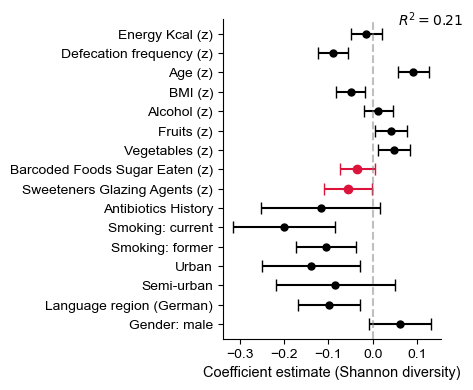

In [11]:
pretty_var_names_v2 = pretty_var_names.copy()

for v in vars_to_scale:
    if v == "eaten_quantity_in_gram":
        pretty_var_names_v2[v + "_z"] = "Total eaten quantity (z)"
    if v == "barcoded_foods_sugar_eaten":
        pretty_var_names_v2[v + "_z"] = "Barcoded Foods Sugar Eaten (z)"
    else:
        pretty_var_names_v2[v + "_z"] = process_string(v) + " (z)"


fig, ax = forest_plot(
    sugar_model_scaled,
    title="",
    figsize=(5, 4),
    r2_annot_loc=(1.1, 1.03),
    pretty_var_names=pretty_var_names_v2,
    highlight_vars=["sweeteners_glazing_agents_z", "barcoded_foods_sugar_eaten_z"],
    base_color="black",
    highlight_color="crimson",
)
sns.despine()

plt.savefig(
    "../figures/additive_descriptive/additive_effects_modeling/forest_plot_barcoded_foods_sugar_eaten.png",
    dpi=300,
    bbox_inches="tight",
)

## Additional Tests
#### 1) Fit nested models to check whether sweeteners stays negative when barcoded sugar is included

In [59]:
# 1) Fit nested models to check whether sweeteners stays negative when barcoded sugar is included

m_full = fit_regression_model(
    bfs_meta,
    ["sweeteners_glazing_agents", "barcoded_foods_sugar_eaten", "vegetables_fruits"],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    robust_regression=False,
    do_robust_se=True,
)

m_no_sugar = fit_regression_model(
    bfs_meta,
    ["sweeteners_glazing_agents", "vegetables_fruits"],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    robust_regression=False,
    do_robust_se=True,
)

m_no_sweet = fit_regression_model(
    bfs_meta,
    ["barcoded_foods_sugar_eaten", "vegetables_fruits"],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    robust_regression=False,
    do_robust_se=True,
)


def _coef_line(res, name):
    return {
        "coef": float(res.params.get(name)),
        "se": float(res.bse.get(name)),
        "p": float(res.pvalues.get(name)),
        "ci_low": (
            float(res.conf_int().loc[name, 0]) if name in res.params.index else None
        ),
        "ci_high": (
            float(res.conf_int().loc[name, 1]) if name in res.params.index else None
        ),
    }


summary_compare = {
    "sweeteners_in_full": _coef_line(m_full, "sweeteners_glazing_agents"),
    "sugar_in_full": _coef_line(m_full, "barcoded_foods_sugar_eaten"),
    "sweeteners_without_sugar": _coef_line(m_no_sugar, "sweeteners_glazing_agents"),
    "sugar_without_sweeteners": _coef_line(m_no_sweet, "barcoded_foods_sugar_eaten"),
}
summary_compare

{'sweeteners_in_full': {'coef': -0.03627254831345581,
  'se': 0.01686267277079385,
  'p': 0.03147180385264917,
  'ci_low': -0.069322779627296,
  'ci_high': -0.0032223169996156223},
 'sugar_in_full': {'coef': -0.002290390501842894,
  'se': 0.001220113454733618,
  'p': 0.06049141465929113,
  'ci_low': -0.004681768930173527,
  'ci_high': 0.00010098792648773926},
 'sweeteners_without_sugar': {'coef': -0.03970320535794385,
  'se': 0.01583427260826782,
  'p': 0.012161537912192176,
  'ci_low': -0.07073780939153788,
  'ci_high': -0.008668601324349812},
 'sugar_without_sweeteners': {'coef': -0.002902162483152509,
  'se': 0.0012030754016236255,
  'p': 0.015852821368158288,
  'ci_low': -0.005260146941020876,
  'ci_high': -0.0005441780252841422}}

### 2) Residualize sweeteners against barcoded sugar + covariates

In [64]:
# 3) Residualize sweeteners against barcoded sugar + covariates
# If sweeteners still has a negative association after orthogonalizing, it is not driven by barcoded sugar overlap.

controls = list(demographic_vars) + ["vegetables_fruits", "barcoded_foods_sugar_eaten"]

m_resid = fit_regression_model(
    bfs_meta,
    controls,
    demographic_vars=[],  # already included as controls above
    dependent_var="sweeteners_glazing_agents",
    robust_regression=False,
    do_robust_se=True,
)

bfs_meta_resid = bfs_meta.copy()
bfs_meta_resid["sweeteners_resid"] = m_resid.resid

m_full_resid = fit_regression_model(
    bfs_meta_resid,
    ["sweeteners_resid", "barcoded_foods_sugar_eaten", "vegetables_fruits"],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    robust_regression=False,
    do_robust_se=True,
)

{
    "sweeteners_resid_effect": _coef_line(m_full_resid, "sweeteners_resid"),
    "sugar_effect": _coef_line(m_full_resid, "barcoded_foods_sugar_eaten"),
}

{'sweeteners_resid_effect': {'coef': -0.03627254831345543,
  'se': 0.016862672770794056,
  'p': 0.03147180385265303,
  'ci_low': -0.06932277962729602,
  'ci_high': -0.003222316999614838},
 'sugar_effect': {'coef': -0.002902162483152602,
  'se': 0.0011815191637184557,
  'p': 0.014037692020195149,
  'ci_low': -0.005217897491084658,
  'ci_high': -0.0005864274752205452}}

## Mediation testing

In [72]:
# Mediation test (product-of-coefficients) with bootstrap CIs
# Mediator: vegetables_fruits
# Outcome: shannon_entropy
# Exposures tested: sweeteners_glazing_agents and barcoded_foods_sugar_eaten

demographic_vars = [
    "age",
    "bmi",
    "gender",
    "language",
    "defecate_quantity_per_day",
    "urbanity",
    "smoking",
    "eaten_quantity_in_gram",
    "antibiotics_treatment",
    "alcohol_eaten",
    "batch",
]


def _get_coef(res, name):
    return float(res.params[name])


def _mediation_point_estimate(df, exposure, mediator, outcome, covars):
    # (A) Total effect: outcome ~ exposure + covars
    m_total = fit_regression_model(
        df,
        [exposure],
        demographic_vars=covars,
        dependent_var=outcome,
        robust_regression=False,
        do_robust_se=True,
    )

    # (B) a-path: mediator ~ exposure + covars
    m_a = fit_regression_model(
        df,
        [exposure],
        demographic_vars=covars,
        dependent_var=mediator,
        robust_regression=False,
        do_robust_se=True,
    )

    # (C) Direct + b-path: outcome ~ exposure + mediator + covars
    m_direct = fit_regression_model(
        df,
        [exposure, mediator],
        demographic_vars=covars,
        dependent_var=outcome,
        robust_regression=False,
        do_robust_se=True,
    )

    c_total = _get_coef(m_total, exposure)
    a = _get_coef(m_a, exposure)
    b = _get_coef(m_direct, mediator)
    c_prime = _get_coef(m_direct, exposure)

    indirect = a * b
    total = c_total
    direct = c_prime

    prop_mediated = None
    if total != 0:
        prop_mediated = indirect / total

    out = {
        "exposure": exposure,
        "mediator": mediator,
        "outcome": outcome,
        "a_exposure_to_mediator": a,
        "b_mediator_to_outcome_given_exposure": b,
        "c_total_effect": total,
        "c_prime_direct_effect": direct,
        "indirect_effect_a_times_b": indirect,
        "proportion_mediated_indirect_over_total": prop_mediated,
        "models": {"total": m_total, "a_path": m_a, "direct": m_direct},
    }
    return out


def _bootstrap_mediation(
    df, exposure, mediator, outcome, covars, n_boot=2000, seed=123
):
    rng = np.random.default_rng(seed)
    n = len(df)

    ind = np.empty(n_boot, dtype=float)
    tot = np.empty(n_boot, dtype=float)
    dirr = np.empty(n_boot, dtype=float)
    a_arr = np.empty(n_boot, dtype=float)
    b_arr = np.empty(n_boot, dtype=float)

    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        dfi = df.iloc[idx]

        est = _mediation_point_estimate(dfi, exposure, mediator, outcome, covars)
        a_arr[i] = est["a_exposure_to_mediator"]
        b_arr[i] = est["b_mediator_to_outcome_given_exposure"]
        ind[i] = est["indirect_effect_a_times_b"]
        tot[i] = est["c_total_effect"]
        dirr[i] = est["c_prime_direct_effect"]

    def _ci(x, lo=2.5, hi=97.5):
        return (float(np.percentile(x, lo)), float(np.percentile(x, hi)))

    out = {
        "exposure": exposure,
        "n_boot": n_boot,
        "a_ci": _ci(a_arr),
        "b_ci": _ci(b_arr),
        "indirect_ci": _ci(ind),
        "total_ci": _ci(tot),
        "direct_ci": _ci(dirr),
        "indirect_boot_samples": ind,
        "total_boot_samples": tot,
        "direct_boot_samples": dirr,
    }
    return out


# Run mediation for both exposures
exposures = ["sweeteners_glazing_agents", "barcoded_foods_sugar_eaten"]
mediator = "vegetables_fruits"
outcome = "shannon_entropy"

results = {}
boot = {}

for x in exposures:
    results[x] = _mediation_point_estimate(
        bfs_meta, x, mediator, outcome, demographic_vars
    )
    boot[x] = _bootstrap_mediation(
        bfs_meta, x, mediator, outcome, demographic_vars, n_boot=2000, seed=123
    )


# Compact view
def _compact(res, bootres):
    return {
        "a": res["a_exposure_to_mediator"],
        "a_ci": bootres["a_ci"],
        "b": res["b_mediator_to_outcome_given_exposure"],
        "b_ci": bootres["b_ci"],
        "indirect": res["indirect_effect_a_times_b"],
        "indirect_ci": bootres["indirect_ci"],
        "total_c": res["c_total_effect"],
        "total_ci": bootres["total_ci"],
        "direct_c_prime": res["c_prime_direct_effect"],
        "direct_ci": bootres["direct_ci"],
        "prop_mediated": res["proportion_mediated_indirect_over_total"],
    }


mediation_summary = {x: _compact(results[x], boot[x]) for x in exposures}
mediation_summary

{'sweeteners_glazing_agents': {'a': 11.801504297529371,
  'a_ci': (-2.0527800891445303, 22.2514996488283),
  'b': 0.00045657551389675515,
  'b_ci': (0.00026301002900144794, 0.0006727749632562376),
  'indirect': 0.005388277889399237,
  'indirect_ci': (-0.0010177013292116837, 0.010552940579354015),
  'total_c': -0.03431492746854386,
  'total_ci': (-0.05757392322715828, -0.0071994165849560395),
  'direct_c_prime': -0.03970320535794458,
  'direct_ci': (-0.06350641837492521, -0.012021482968588912),
  'prop_mediated': -0.15702431235906344},
 'barcoded_foods_sugar_eaten': {'a': -0.9928967586368727,
  'a_ci': (-1.8406099946187484, -0.09038499465812465),
  'b': 0.0003854370224584381,
  'b_ci': (0.0001751989195407005, 0.0006115717633857908),
  'indirect': -0.00038269917025763066,
  'indirect_ci': (-0.0008619293839181236, -3.027799434904662e-05),
  'total_c': -0.0032848616534103415,
  'total_ci': (-0.005552838870369217, -0.0008750237167676131),
  'direct_c_prime': -0.0029021624831526345,
  'direc

In [ ]:
# significance check for indirect effect via bootstrap (two-sided)
# If 0 is not inside indirect_ci, evidence of statistical mediation.

for x in exposures:
    lo, hi = mediation_summary[x]["indirect_ci"]
    print(x, "indirect_ci:", (lo, hi), "contains_0:", (lo <= 0 <= hi))

sweeteners_glazing_agents indirect_ci: (-0.0010177013292116837, 0.010552940579354015) contains_0: True
barcoded_foods_sugar_eaten indirect_ci: (-0.0008619293839181236, -3.027799434904662e-05) contains_0: False


# Joint-exposure mediation (conditional indirect effects)

In [78]:
def _joint_mediation_point_estimate(
    df, exposure, other_exposure, mediator, outcome, covars
):
    # (A) Total effect (both exposures in model)
    m_total = fit_regression_model(
        df,
        [exposure, other_exposure],
        demographic_vars=covars,
        dependent_var=outcome,
        robust_regression=False,
        do_robust_se=True,
    )

    # (B) Mediator model (both exposures)
    m_a = fit_regression_model(
        df,
        [exposure, other_exposure],
        demographic_vars=covars,
        dependent_var=mediator,
        robust_regression=False,
        do_robust_se=True,
    )

    # (C) Direct + b-path (both exposures + mediator)
    m_direct = fit_regression_model(
        df,
        [exposure, other_exposure, mediator],
        demographic_vars=covars,
        dependent_var=outcome,
        robust_regression=False,
        do_robust_se=True,
    )

    c_total = float(m_total.params[exposure])
    a = float(m_a.params[exposure])
    b = float(m_direct.params[mediator])
    c_prime = float(m_direct.params[exposure])

    indirect = a * b

    prop_mediated = None
    if c_total != 0:
        prop_mediated = indirect / c_total

    return {
        "exposure": exposure,
        "a": a,
        "b": b,
        "c_total": c_total,
        "c_prime": c_prime,
        "indirect": indirect,
        "prop_mediated": prop_mediated,
        "models": {"total": m_total, "a_path": m_a, "direct": m_direct},
    }

In [79]:
def _joint_bootstrap_mediation(
    df, exposure, other_exposure, mediator, outcome, covars, n_boot=2000, seed=123
):
    rng = np.random.default_rng(seed)
    n = len(df)

    ind = np.empty(n_boot)
    tot = np.empty(n_boot)
    dirr = np.empty(n_boot)
    a_arr = np.empty(n_boot)
    b_arr = np.empty(n_boot)

    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        dfi = df.iloc[idx]

        est = _joint_mediation_point_estimate(
            dfi, exposure, other_exposure, mediator, outcome, covars
        )

        a_arr[i] = est["a"]
        b_arr[i] = est["b"]
        ind[i] = est["indirect"]
        tot[i] = est["c_total"]
        dirr[i] = est["c_prime"]

    def _ci(x):
        return (float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5)))

    return {
        "a_ci": _ci(a_arr),
        "b_ci": _ci(b_arr),
        "indirect_ci": _ci(ind),
        "total_ci": _ci(tot),
        "direct_ci": _ci(dirr),
    }

In [80]:
joint_results = {}
joint_boot = {}

joint_results["sweeteners_glazing_agents"] = _joint_mediation_point_estimate(
    bfs_meta,
    exposure="sweeteners_glazing_agents",
    other_exposure="barcoded_foods_sugar_eaten",
    mediator="vegetables_fruits",
    outcome="shannon_entropy",
    covars=demographic_vars,
)

joint_results["barcoded_foods_sugar_eaten"] = _joint_mediation_point_estimate(
    bfs_meta,
    exposure="barcoded_foods_sugar_eaten",
    other_exposure="sweeteners_glazing_agents",
    mediator="vegetables_fruits",
    outcome="shannon_entropy",
    covars=demographic_vars,
)

joint_boot["sweeteners_glazing_agents"] = _joint_bootstrap_mediation(
    bfs_meta,
    "sweeteners_glazing_agents",
    "barcoded_foods_sugar_eaten",
    "vegetables_fruits",
    "shannon_entropy",
    demographic_vars,
)

joint_boot["barcoded_foods_sugar_eaten"] = _joint_bootstrap_mediation(
    bfs_meta,
    "barcoded_foods_sugar_eaten",
    "sweeteners_glazing_agents",
    "vegetables_fruits",
    "shannon_entropy",
    demographic_vars,
)

In [81]:
joint_summary = {
    k: {
        "a": joint_results[k]["a"],
        "a_ci": joint_boot[k]["a_ci"],
        "b": joint_results[k]["b"],
        "b_ci": joint_boot[k]["b_ci"],
        "indirect": joint_results[k]["indirect"],
        "indirect_ci": joint_boot[k]["indirect_ci"],
        "total": joint_results[k]["c_total"],
        "total_ci": joint_boot[k]["total_ci"],
        "direct": joint_results[k]["c_prime"],
        "direct_ci": joint_boot[k]["direct_ci"],
        "prop_mediated": joint_results[k]["prop_mediated"],
    }
    for k in joint_results
}

joint_summary

{'sweeteners_glazing_agents': {'a': 13.455358567855356,
  'a_ci': (0.3023066942633935, 23.439558239144386),
  'b': 0.0004328275761289523,
  'b_ci': (0.0002386832099779933, 0.0006486653958533359),
  'indirect': 0.0058238502348707645,
  'indirect_ci': (0.00014181526102020789, 0.010996756601971412),
  'total': -0.03044869807858282,
  'total_ci': (-0.054547900821315276, -0.0025036716346218926),
  'direct': -0.03627254831345512,
  'direct_ci': (-0.06064603501760065, -0.008069108223582623),
  'prop_mediated': -0.19126762726736016},
 'barcoded_foods_sugar_eaten': {'a': -1.2023798046878782,
  'a_ci': (-2.0298367630539365, -0.29405786723257754),
  'b': 0.0004328275761288589,
  'b_ci': (0.00023868320997808177, 0.0006486653958533945),
  'indirect': -0.0005204231364493451,
  'indirect_ci': (-0.0010124707663264514, -0.0001148781615019132),
  'total': -0.0028108136382924416,
  'total_ci': (-0.005123589122459318, -0.0004781165662688001),
  'direct': -0.0022903905018429095,
  'direct_ci': (-0.00458479

In [82]:
for x in joint_summary:
    lo, hi = joint_summary[x]["indirect_ci"]
    print(x, "joint indirect_ci:", (lo, hi), "contains_0:", (lo <= 0 <= hi))

sweeteners_glazing_agents joint indirect_ci: (0.00014181526102020789, 0.010996756601971412) contains_0: False
barcoded_foods_sugar_eaten joint indirect_ci: (-0.0010124707663264514, -0.0001148781615019132) contains_0: False
